Target variables  :  ['malignant' 'benign']
Unique values of the target variable [0 1]
Counts of the target variable : [212 357]


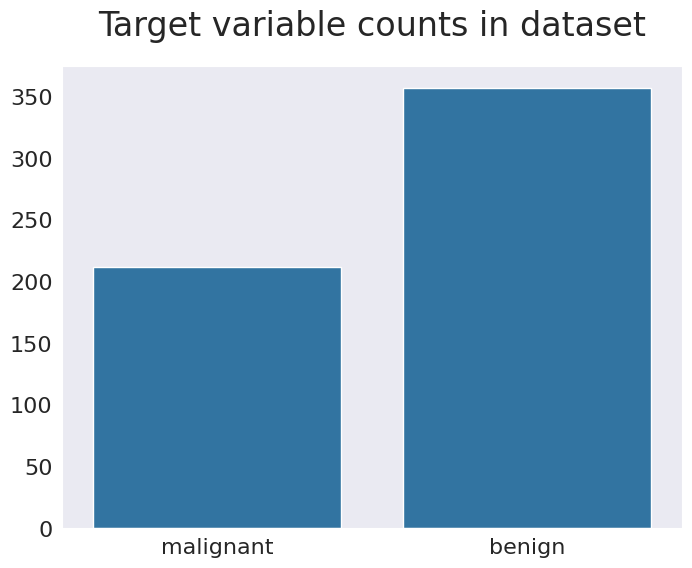

In [1]:
import numpy as np # Import NumPy for numerical operations, aliased as 'np'
import seaborn as sns # Import Seaborn for statistical data visualization, aliased as 'sns'
import matplotlib.pyplot as plt # Import Matplotlib for plotting, aliased as 'plt'
from sklearn.datasets import load_breast_cancer # Import the breast cancer dataset from scikit-learn

dataset = load_breast_cancer() # Load the breast cancer dataset into the 'dataset' variable

sns.set_style('dark') # Set the Seaborn plot style to 'dark'
import matplotlib as mpl # Import Matplotlib for general configuration, aliased as 'mpl'
mpl.style.use(['https://gist.githubusercontent.com/BrendanMartin/01e71bb9550774e2ccff3af7574c0020/raw/6fa9681c7d0232d34c9271de9be150e584e606fe/lds_default.mplstyle']) # Apply a custom Matplotlib style from a URL
mpl.rcParams.update({"figure.figsize": (8,6), "axes.titlepad": 22.0}) # Update Matplotlib's default figure size and title padding

print('Target variables  : ', dataset['target_names']) # Print the names of the target classes (e.g., 'malignant', 'benign')

(unique, counts) = np.unique(dataset['target'], return_counts=True) # Get unique values and their counts from the target variable

print('Unique values of the target variable', unique) # Print the unique numerical labels of the target variable (0 and 1)
print('Counts of the target variable :', counts) # Print the number of occurrences for each unique target label

sns.barplot(x=dataset['target_names'], y=counts) # Create a bar plot showing the counts of each target variable
plt.title('Target variable counts in dataset') # Set the title of the bar plot
plt.show() # Display the plot

Automatically created module for IPython interactive environment


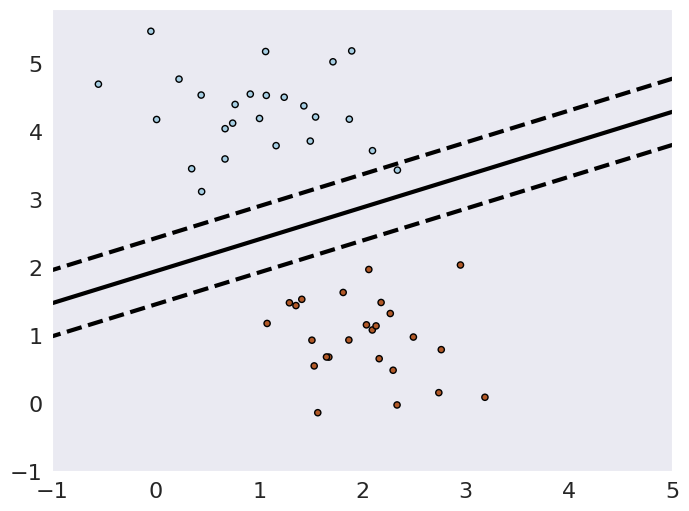

In [2]:
#Maximum margin separating hyperplane

print(__doc__) # Print the docstring of the module (often empty or a comment at the top of the file)

import numpy as np # Import NumPy for numerical operations, aliased as 'np'
import matplotlib.pyplot as plt # Import Matplotlib for plotting, aliased as 'plt'
from sklearn.linear_model import SGDClassifier # Import SGDClassifier for linear classification using Stochastic Gradient Descent
from sklearn.datasets import make_blobs # Import make_blobs to generate synthetic isotropic Gaussian blobs

# we create 50 separable points
X, Y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60) # Generate 50 data points with 2 distinct clusters

# fit the model
clf = SGDClassifier(loss="hinge", alpha=0.01, max_iter=200) # Initialize an SGDClassifier with hinge loss (linear SVM), regularization alpha, and max iterations

clf.fit(X, Y) # Train the classifier using the generated data (features X, labels Y)

# plot the line, the points, and the nearest vectors to the plane
xx = np.linspace(-1, 5, 10) # Create a range of x-values for plotting the decision boundary
yy = np.linspace(-1, 5, 10) # Create a range of y-values for plotting the decision boundary

X1, X2 = np.meshgrid(xx, yy) # Create a 2D grid of points from xx and yy
Z = np.empty(X1.shape) # Initialize an empty array to store the decision function values for each grid point
for (i, j), val in np.ndenumerate(X1): # Iterate over each point in the grid
    x1 = val # Get the x-coordinate of the current grid point
    x2 = X2[i, j] # Get the y-coordinate of the current grid point
    p = clf.decision_function([[x1, x2]]) # Calculate the decision function value for the current point
    Z[i, j] = p[0] # Store the decision function value in the Z array
levels = [-1.0, 0.0, 1.0] # Define contour levels: -1.0, 0.0 (decision boundary), and 1.0
linestyles = ['dashed', 'solid', 'dashed'] # Define line styles for the contour levels
colors = 'k' # Set the color of the contour lines to black
plt.contour(X1, X2, Z, levels, colors=colors, linestyles=linestyles) # Plot the contour lines (decision boundary and margins)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Paired,
            edgecolor='black', s=20) # Plot the original data points, colored by their labels

plt.axis('tight') # Adjust the plot limits to fit the data tightly
plt.show() # Display the plot